In [1]:
import sys
import os
import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
import numpy as np
import torch
import random
import torch.nn.functional as F

In [2]:
np.random.seed(0)
torch.manual_seed(0)
random.seed(0)

In [3]:
def read_parameters(file_path):
    params = {}

    # First pass: read and store values as strings
    with open(file_path, 'r') as file:
        for line in file:
            # Skip empty lines and comments (if any)
            line = line.strip()
            if line and not line.startswith('#'):
                # Split the line at the equals sign
                key, value = line.split('=')
                key = key.strip()
                value = value.strip()

                # Store the parameter as a string for now
                params[key] = value

    # Second pass: evaluate expressions and convert values
    for key, value in params.items():
        try:
            # Try to evaluate the value as a Python expression using previously defined parameters
            params[key] = eval(value, {}, params)
        except:
            # If it's not an expression, check if it can be converted to float or int
            if '.' in value:
                params[key] = float(value)
            else:
                params[key] = int(value)
        
        # Set the variable in the global namespace with the evaluated value
        globals()[key] = params[key]

    return params

In [4]:
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "..")))
from ants_move import *
sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

pygame 2.6.1 (SDL 2.28.4, Python 3.13.3)
Hello from the pygame community. https://www.pygame.org/contribute.html


/home/alepitt/Explorables/.venv/lib/python3.13/site-packages/pygame/pkgdata.py:25: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_stream, resource_exists


In [5]:
work_folder = 'edge_spen'
saving_folder = 'l0'
os.chdir(work_folder)

In [6]:
file_path = saving_folder + '/parameters.txt'  # Path to the parameters file
parameters = read_parameters(file_path)

for key, value in parameters.items():
    print(f"{key} = {value}")

n = 300
Lx = 32
Ly = 32
delta = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]
eta = 0.01
decay_rate = 0.015
eta_special = 1
n_special = 30
t_transient = 200
tmax = 1200
batch_size = 60
gamma = 0.99
state_dim = (4, 9, 9)
action_dim = 8
action_bound = 1
vision = 9
actor_lr = 5e-06
critic_lr = 5e-05
weight_decay = 0.0
clip_epsilon = 0.2
entropy_coeff = 0.05
policy_steps = 1000
learning_steps = 1
clip_grad = False
use_gae = True
lam = 0.95


In [7]:
eta_special = 0.01
eta = 0.01
n = 300
n_special = 300

In [8]:
def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta + n_special*eta_special)/(decay_rate*Lx**2)

In [9]:
vision=state_dim[-1]
from ppo_ants import *

In [10]:
def setup_environment(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                        tmax, n_special, t_transient, vision,
                        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
                        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                        state_dim, action_dim, clip_grad):
    
    env = Ants(n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
            tmax, n_special, t_transient, vision=state_dim[-1])
    
    sys.path.append(os.path.abspath(os.path.join(os.getcwd(), "../../../..")))

    config_net_file = f"{saving_folder}/networks.yaml"
    ppo_ants = PPO_ants( env,
                    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay, config_net_file,
                    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                    state_dim, action_dim, clip_grad)

    return env, ppo_ants

In [11]:
env, ppo_ants = setup_environment(
    n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
    tmax, n_special, t_transient, vision,
    gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
    clip_epsilon, entropy_coeff, policy_steps, learning_steps,
    state_dim, action_dim, clip_grad
)

In [12]:
critic_test = 'weights/critic.pth'
actor_test = 'weights/actor.pth'

In [13]:
def load_policy_weights(ppo_ants, actor_test, critic_test):
    if not os.path.exists(f"{saving_folder}/{critic_test}"):
        print(f"Warning: {critic_test} or {actor_test} not found in {saving_folder}. Using default weights.")
    else:
        ppo_ants.critic.load_state_dict(torch.load(f"{saving_folder}/{critic_test}", weights_only=True))
        ppo_ants.actor.load_state_dict(torch.load(f"{saving_folder}/{actor_test}", weights_only=True))

In [13]:
positions = np.zeros((len(beta), len(delta), env.num, 2))
pheromones = np.zeros((len(beta), len(delta), env.Lx, env.Ly))

for b in beta:
    for d in delta:
        print(f"Testing with delta = {d}, beta = {b}")

        env, ppo_ants = setup_environment(
            n, Lx, Ly, delta, beta, decay_rate, eta, eta,
            tmax, n_special, t_transient, vision,
            gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
            clip_epsilon, entropy_coeff, policy_steps, learning_steps,
            state_dim, action_dim, clip_grad
        )

        ppo_ants.setup_networks()

        load_policy_weights(ppo_ants, actor_test, critic_test)

        ppo_ants.env.reset_objects()
        ppo_ants.env.delta[:] = d
        ppo_ants.env.beta[:] = b
        ppo_ants.env.transient()
        results = ppo_ants.test_episode(max_prob=False, save_pos = True, reset=False)
        print('delta=', ppo_ants.env.delta[0], 'beta=', ppo_ants.env.beta[0])


        final_positions = ppo_ants.env.positions.copy()
        final_field = ppo_ants.env.pheromones.copy()

        positions[beta.index(b), delta.index(d), :, :] = final_positions
        pheromones[beta.index(b), delta.index(d), :, :] = final_field

Testing with delta = 0.3, beta = 3.5
delta= 0.3 beta= 3.5
Testing with delta = 0.4, beta = 3.5
delta= 0.4 beta= 3.5
Testing with delta = 0.5, beta = 3.5
delta= 0.5 beta= 3.5
Testing with delta = 0.6, beta = 3.5
delta= 0.6 beta= 3.5
Testing with delta = 0.7, beta = 3.5
delta= 0.7 beta= 3.5
Testing with delta = 0.8, beta = 3.5
delta= 0.8 beta= 3.5
Testing with delta = 0.3, beta = 4.5
delta= 0.3 beta= 4.5
Testing with delta = 0.4, beta = 4.5
delta= 0.4 beta= 4.5
Testing with delta = 0.5, beta = 4.5
delta= 0.5 beta= 4.5
Testing with delta = 0.6, beta = 4.5
delta= 0.6 beta= 4.5
Testing with delta = 0.7, beta = 4.5
delta= 0.7 beta= 4.5
Testing with delta = 0.8, beta = 4.5
delta= 0.8 beta= 4.5
Testing with delta = 0.3, beta = 5.5
delta= 0.3 beta= 5.5
Testing with delta = 0.4, beta = 5.5
delta= 0.4 beta= 5.5
Testing with delta = 0.5, beta = 5.5
delta= 0.5 beta= 5.5
Testing with delta = 0.6, beta = 5.5
delta= 0.6 beta= 5.5
Testing with delta = 0.7, beta = 5.5
delta= 0.7 beta= 5.5
Testing with d

In [ ]:
save = True
if save:
    np.savez_compressed(
    "simulation_results_rand_etalow_300_300_"+saving_folder+".npz",
    positions=positions,
    pheromones=pheromones,
    )

NameError: name 'positions' is not defined

In [ ]:
# Run simulation for saving_folder = l2 ... l8
from pathlib import Path

folders = [f"l{i}" for i in range(1,2)]

In [ ]:
# Ensure we are in work_folder
cwd = Path.cwd()
if cwd.name != work_folder and (cwd / work_folder).exists():
    os.chdir(cwd / work_folder)

all_results = {}

for sf in folders:
    print(f"\n===== Running {sf} =====")
    saving_folder = sf

    # Load parameters for this folder (updates globals)
    parameters = read_parameters(f"{saving_folder}/parameters.txt")
    vision = state_dim[-1]

    env, ppo_ants = setup_environment(
        n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
        tmax, n_special, t_transient, vision,
        gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
        clip_epsilon, entropy_coeff, policy_steps, learning_steps,
        state_dim, action_dim, clip_grad
    )

    positions = np.zeros((len(beta), len(delta), env.num, 2))
    pheromones = np.zeros((len(beta), len(delta), env.Lx, env.Ly))

    for b in beta:
        for d in delta:
            env, ppo_ants = setup_environment(
                n, Lx, Ly, delta, beta, decay_rate, eta, eta_special,
                tmax, n_special, t_transient, vision,
                gamma, action_bound, actor_lr, critic_lr, batch_size, weight_decay,
                clip_epsilon, entropy_coeff, policy_steps, learning_steps,
                state_dim, action_dim, clip_grad
            )
            ppo_ants.setup_networks()
            load_policy_weights(ppo_ants, actor_test, critic_test)

            ppo_ants.env.reset_objects()
            ppo_ants.env.delta[:] = d
            ppo_ants.env.beta[:] = b
            ppo_ants.env.transient()
            _ = ppo_ants.test_episode(max_prob=False, save_pos=True, reset=False)

            positions[beta.index(b), delta.index(d), :, :] = ppo_ants.env.positions.copy()
            pheromones[beta.index(b), delta.index(d), :, :] = ppo_ants.env.pheromones.copy()

    out_name = f"simulation_results_rand_{saving_folder}.npz"
    np.savez_compressed(out_name, positions=positions, pheromones=pheromones)
    all_results[saving_folder] = {"positions": positions, "pheromones": pheromones}
    print(f"Saved: {out_name}")

print("\nDone.")


===== Running l1 =====
Saved: simulation_results_rand_l1.npz

Done.


In [14]:
load = True
if load:
    data = np.load("simulation_results_rand_"+saving_folder+".npz")
    positions = data["positions"]
    pheromones = data["pheromones"]

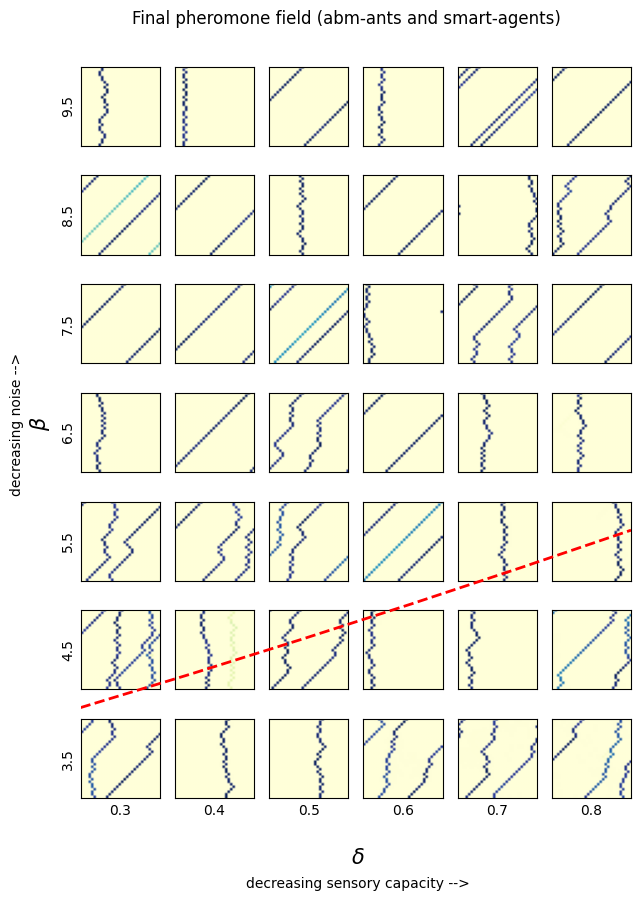

In [15]:
from matplotlib.gridspec import GridSpec

fig = plt.figure(figsize=(6,8))
gs = GridSpec(len(beta), len(delta), figure=fig)

# subplot della griglia
ax = np.empty((len(beta), len(delta)), dtype=object)
for i in range(len(beta)):
    for j in range(len(delta)):
        ax[i,j] = fig.add_subplot(gs[i,j])
        ax[i,j].imshow(pheromones[len(beta)-i-1,j][::-1], cmap='YlGnBu')
        ax[i,j].set_xticks([])
        ax[i,j].set_yticks([])
        if j == 0:
            ax[i,j].set_ylabel(f'{beta[len(beta)-i-1]}', fontsize=10)
        if i == len(beta)-1:
            ax[i,j].set_xlabel(f'{delta[j]}', fontsize=10)

# asse globale che copre tutto il gridspec
ax_curve = fig.add_subplot(gs[:,:], frameon=False)
ax_curve.plot(delta, [beta_crit(d, s0) for d in delta],
              color='red', linestyle='--', linewidth=2)
ax_curve.set_xlim(min(delta), max(delta))
ax_curve.set_ylim(min(beta), max(beta))
ax_curve.set_xticks([])
ax_curve.set_yticks([])

fig.text(-0.03, 0.52, r'$\beta$', fontsize=15, va='center', rotation='vertical')
fig.text(-0.06, 0.52, r'decreasing noise -->', fontsize=10, va='center', rotation='vertical')
fig.text(0.52, -0.03, r'$\delta$', fontsize=15, ha='center')
fig.text(0.52, -0.06, r'decreasing sensory capacity -->', fontsize=10, ha='center')
# title('Final positions of the ants', fontsize=16)
fig.text(0.5, 1.02, 'Final pheromone field (abm-ants and smart-agents)', fontsize=12, ha='center')

plt.tight_layout()
plt.savefig('test_pher_gridplot.png')
plt.show()

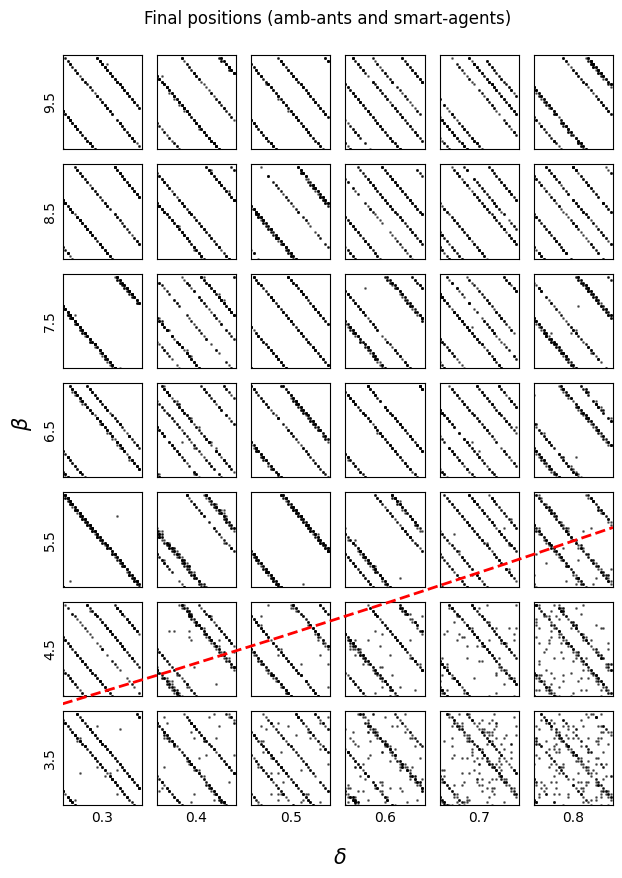

In [16]:
fig, ax = plt.subplots(len(beta), len(delta), figsize=(6,8))

for i,b in enumerate(beta):
    for j,d in enumerate(delta):

        ax[i,j].scatter(positions[len(beta)-i-1,j,:,1],positions[len(beta)-i-1,j,:,0], s=1, c='black', alpha=0.5)
        ax[i,j].set_xlim(0,Lx)
        ax[i,j].set_ylim(0,Ly)
        ax[i,j].set_xticks([])
        ax[i,j].set_yticks([])

        if j == 0:
            ax[i,j].set_ylabel(f'{beta[len(beta)-i-1]}', fontsize=10)

        if i == len(beta) - 1:
            ax[i,j].set_xlabel(f'{d}', fontsize=10)

# asse globale che copre tutto il gridspec
ax_curve = fig.add_subplot(gs[:,:], frameon=False)
ax_curve.plot(delta, [beta_crit(d, s0) for d in delta],
              color='red', linestyle='--', linewidth=2)
ax_curve.set_xlim(min(delta), max(delta))
ax_curve.set_ylim(min(beta), max(beta))
ax_curve.set_xticks([])
ax_curve.set_yticks([])

fig.text(-0.03, 0.52, r'$\beta$', fontsize=15, va='center', rotation='vertical')
#fig.text(-0.06, 0.52, r'decreasing noise -->', fontsize=10, va='center', rotation='vertical')
fig.text(0.52, -0.03, r'$\delta$', fontsize=15, ha='center')
#fig.text(0.52, -0.06, r'decreasing sensory capacity -->', fontsize=10, ha='center')
# title('Final positions of the ants', fontsize=16)
fig.text(0.5, 1.02, 'Final positions (amb-ants and smart-agents)', fontsize=12, ha='center')

plt.tight_layout()
plt.savefig('test_ants_gridplot.png')
plt.show()

In [19]:
def order_parameter(pheromone, position):
    ns0 = np.mean(pheromone)
    plus_id = pheromone > ns0
    minus_id = pheromone <= ns0
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)
    
    position = np.array(position, dtype=int)
    rho = np.bincount(np.array(position[:env.n,0]*Ly + position[:env.n,1]), minlength=Lx*Ly)
    rho = rho.reshape((Lx, Ly))
    mu_plus = np.sum(rho[plus_id])
    mu_minus = np.sum(rho[minus_id])

    if n_plus == 0 or n_minus == 0:
        return -1
    else:
        local_op = (mu_plus - mu_minus)/env.n
        return local_op
    
order_parameters = np.zeros((len(beta), len(delta)))
for i,b in enumerate(beta):
    for j,d in enumerate(delta):
        order_parameters[i,j] = order_parameter(pheromones[i,j], positions[i,j])

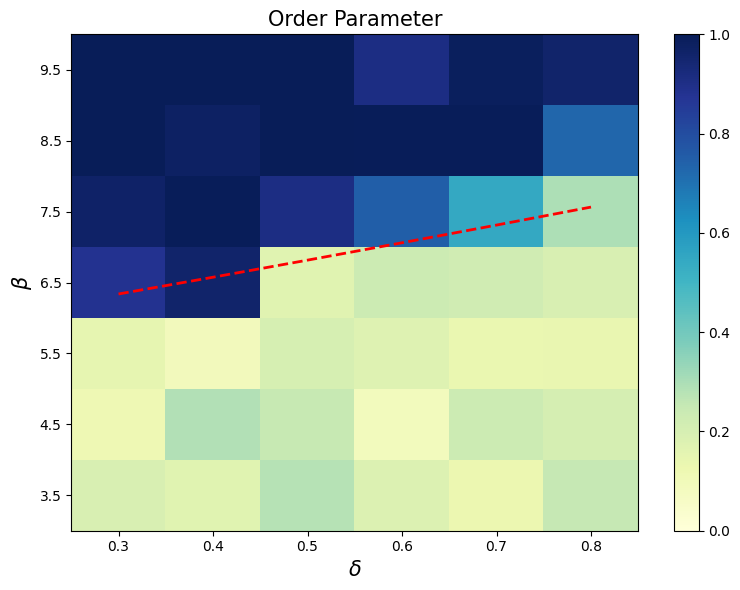

In [20]:
plt.figure(figsize=(8, 6))
plt.imshow(order_parameters, cmap='YlGnBu', aspect='auto', vmin=0, vmax=1)

# curva critica
beta_curve = np.array([beta_crit(d, s0) for d in delta])

# limiti
beta_min, beta_max = min(beta), max(beta)

# taglio ai limiti per non uscire dal colormap
beta_curve_clipped = np.clip(beta_curve, beta_min, beta_max)

# interpolazione sugli indici
beta_idx = np.interp(beta_curve_clipped, beta, np.arange(len(beta)))

plt.plot(np.arange(len(delta)), beta_idx, color='red', linestyle='--', linewidth=2)

# etichette e formattazione
plt.colorbar()
plt.xticks(ticks=np.arange(len(delta)), labels=delta)
plt.yticks(ticks=np.arange(len(beta)), labels=beta)
plt.xlabel(r'$\delta$', fontsize=15)
plt.ylabel(r'$\beta$', fontsize=15)
plt.title('Order Parameter', fontsize=15)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()